# 06 · Desain Eksperimen & Pemodelan Baseline
**Proyek Terintegrasi DA & DS – Kelompok 25 · Daniel Haganta Ginting (41426090)**

| Aspek | Keterangan |
|---|---|
| **Input** | `../warehouse/cabai_medan.db` (`v_harga_lengkap`, auto-fallback ke `../data/processed/01_clean.csv` + `01_cuaca_harian.csv`) dan `../data/processed/05_fitur_final_uas.json` |
| **Output** | Evaluasi komparatif baseline (Naif, Ridge Level, Ridge Delta, Huber Delta) + desain eksperimen model lanjutan (`models/train.py`) |
| **Fokus Utama** | Prediksi harga harian cabai merah keriting pada **`Pasar Tradisional`** Kota Medan (validasi tambahan pada panel 4 level pasar) |
| **Validasi** | Berbasis waktu: Train `2020-01-28` s.d. `2024-12-31`, Test `2025-01-01` s.d. `2026-01-29`, CV `TimeSeriesSplit(n_splits=5)`, `random_state = 42` |
| **Metrik** | **MAE (Rp/kg)** sebagai metrik utama, didampingi RMSE (Rp/kg), MAPE (%), dan $R^2$ |

## 1 · Setup, Pemuatan Data (Auto-Fallback Warehouse -> CSV), & Rekonstruksi Fitur

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import sqlite3
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.base import clone
from sklearn.linear_model import HuberRegressor, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path("..")
PROC = ROOT / "data" / "processed"
DB_PATH = ROOT / "warehouse" / "cabai_medan.db"

PASAR_URUT = ["Produsen", "Pedagang Besar", "Pasar Tradisional", "Pasar Modern"]
TARGET = "Harga_Cabai_Merah_Keriting"
SPLIT_DATE = pd.Timestamp("2024-12-31")

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
})
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)


def muat_data_sumber() -> tuple[pd.DataFrame, pd.DataFrame, str]:
    """Muat data harga dari warehouse SQLite jika tersedia, fallback otomatis ke CSV bersih."""
    cuaca = (
        pd.read_csv(PROC / "01_cuaca_harian.csv", parse_dates=["Tanggal"])
        .sort_values("Tanggal")
        .set_index("Tanggal")
        .asfreq("D")
    )

    sumber_label = ""
    df_harga = None
    if DB_PATH.is_file():
        try:
            with sqlite3.connect(DB_PATH) as con:
                cek = con.execute(
                    "SELECT name FROM sqlite_master WHERE type IN ('view','table') AND name='v_harga_lengkap'"
                ).fetchone()
                if cek:
                    raw_db = pd.read_sql("SELECT * FROM v_harga_lengkap", con)
                    rename_map = {
                        "tanggal": "Tanggal",
                        "kategori_pasar": "Kategori_Pasar",
                        "harga_cabai_keriting": "Harga_Cabai_Merah_Keriting",
                        "curah_hujan_mm": "Curah_Hujan_mm",
                    }
                    raw_db = raw_db.rename(columns={k: v for k, v in rename_map.items() if k in raw_db.columns})
                    wajib = {"Tanggal", "Kategori_Pasar", TARGET}
                    if wajib.issubset(raw_db.columns):
                        raw_db["Tanggal"] = pd.to_datetime(raw_db["Tanggal"])
                        df_harga = raw_db
                        sumber_label = f"SQLite Warehouse ({DB_PATH})"
        except Exception as exc:
            print(f"[peringatan] Gagal membaca warehouse SQLite ({exc}), beralih ke fallback CSV.")

    if df_harga is None:
        df_harga = pd.read_csv(PROC / "01_clean.csv", parse_dates=["Tanggal"])
        sumber_label = f"Fallback CSV ({PROC / '01_clean.csv'})"

    df_harga = df_harga.sort_values(["Kategori_Pasar", "Tanggal"]).reset_index(drop=True)
    return df_harga, cuaca, sumber_label


def bangun_fitur_bebas_leakage(df_harga: pd.DataFrame, cuaca: pd.DataFrame) -> pd.DataFrame:
    """Rekonstruksi fitur final berbasis riwayat <= H-1 (konsisten dengan NB03 dan NB05)."""
    df = df_harga.copy()
    df["Bulan"] = df["Tanggal"].dt.month

    g = df.groupby("Kategori_Pasar")[TARGET]
    df["Harga_Lag1"] = g.shift(1)
    df["Harga_Lag5"] = g.shift(5)
    df["Harga_Lag20"] = g.shift(20)
    df["Harga_MA7"] = g.transform(lambda s: s.shift(1).rolling(7).mean())
    df["Harga_MA20"] = g.transform(lambda s: s.shift(1).rolling(20).mean())

    wide = df.pivot(index="Tanggal", columns="Kategori_Pasar", values=TARGET)
    hulu = wide[["Produsen", "Pedagang Besar"]].shift(1).rename(
        columns={"Produsen": "Harga_Produsen_Lag1", "Pedagang Besar": "Harga_PB_Lag1"}
    )
    df = df.merge(hulu, left_on="Tanggal", right_index=True, how="left")

    cal = pd.DataFrame(index=cuaca.index)
    cal["Akumulasi_Hujan_7H"] = cuaca["Curah_Hujan_mm"].shift(1).rolling(7).sum()
    df = df.merge(cal, left_on="Tanggal", right_index=True, how="left")

    libur = holidays.country_holidays("ID", years=range(2019, 2028))
    idul_fitri = sorted(pd.Timestamp(d) for d, n in libur.items() if "Hari Raya Idul Fitri" in n.split("; "))
    df["Hari_Menuju_Idul_Fitri"] = df["Tanggal"].apply(
        lambda t: next(((d - t).days for d in idul_fitri if d >= t), np.nan)
    )
    df["Is_Musim_Hujan"] = df["Bulan"].isin([9, 10, 11, 12]).astype(int)
    df["Level_Rantai_Pasok"] = df["Kategori_Pasar"].map(dict(zip(PASAR_URUT, [1, 2, 3, 4])))
    df["Interaksi_Lag1_x_MusimHujan"] = df["Harga_Lag1"] * df["Is_Musim_Hujan"]

    # Buang 20 hari kerja awal tiap pasar yang belum memiliki riwayat lengkap
    df = (
        df.dropna(subset=["Harga_Lag20", "Harga_MA20", "Akumulasi_Hujan_7H", "Hari_Menuju_Idul_Fitri"])
        .sort_values(["Tanggal", "Kategori_Pasar"])
        .reset_index(drop=True)
    )
    return df


fitur_cfg = json.loads((PROC / "05_fitur_final_uas.json").read_text(encoding="utf-8"))
FITUR_LINEAR = fitur_cfg["fitur_untuk_model_linear"]
FITUR_POHON = fitur_cfg["fitur_terpilih_tahap4"]

df_raw, cuaca_df, sumber_data = muat_data_sumber()
df_panel = bangun_fitur_bebas_leakage(df_raw, cuaca_df)
df_trad = df_panel[df_panel["Kategori_Pasar"] == "Pasar Tradisional"].sort_values("Tanggal").reset_index(drop=True)

print(f"Sumber data aktif  : {sumber_data}")
print(f"Data panel bersih  : {df_panel.shape} | {df_panel['Tanggal'].min().date()} s.d. {df_panel['Tanggal'].max().date()}")
print(f"Fokus Tradisional  : {df_trad.shape} | Train <= {SPLIT_DATE.date()}: {(df_trad['Tanggal'] <= SPLIT_DATE).sum()} hari | Test >= 2025-01-01: {(df_trad['Tanggal'] > SPLIT_DATE).sum()} hari")
print(f"Fitur linear (10)  : {FITUR_LINEAR}")
print(f"Fitur pohon  (12)  : {FITUR_POHON}")

Sumber data aktif  : Fallback CSV (..\data\processed\01_clean.csv)
Data panel bersih  : (6272, 23) | 2020-01-28 s.d. 2026-01-29
Fokus Tradisional  : (1568, 23) | Train <= 2024-12-31: 1286 hari | Test >= 2025-01-01: 282 hari
Fitur linear (10)  : ['Harga_Lag1', 'Harga_Lag5', 'TE_Pasar_Bulan', 'Harga_Lag20', 'Harga_Produsen_Lag1', 'Harga_PB_Lag1', 'Interaksi_Lag1_x_MusimHujan', 'Level_Rantai_Pasok', 'Hari_Menuju_Idul_Fitri', 'Akumulasi_Hujan_7H']
Fitur pohon  (12)  : ['Harga_Lag1', 'Harga_MA7', 'Harga_Lag5', 'TE_Pasar_Bulan', 'Harga_MA20', 'Harga_Lag20', 'Harga_Produsen_Lag1', 'Harga_PB_Lag1', 'Interaksi_Lag1_x_MusimHujan', 'Level_Rantai_Pasok', 'Hari_Menuju_Idul_Fitri', 'Akumulasi_Hujan_7H']


## 2 · Problem Framing & Karakteristik Target (`Price Stickiness`)
Sebelum melatih model regresi, kita periksa terlebih dahulu sifat deret waktu harga di **Pasar Tradisional**: seberapa sering harga harian stagnan vs berubah, serta seberapa besar lonjakan ekstrem harian.

In [2]:
for nama_split, sub in [
    ("Train (2020-2024)", df_trad[df_trad["Tanggal"] <= SPLIT_DATE]),
    ("Test  (2025-2026)", df_trad[df_trad["Tanggal"] > SPLIT_DATE]),
]:
    dy = sub[TARGET] - sub["Harga_Lag1"]
    tetap_pct = (dy == 0).mean() * 100
    naik_pct = (dy > 0).mean() * 100
    turun_pct = (dy < 0).mean() * 100
    print(
        f"{nama_split} (n={len(sub):4d}) | "
        f"Mean=Rp{sub[TARGET].mean():,.0f} | Median=Rp{sub[TARGET].median():,.0f} | "
        f"Min-Max=Rp{sub[TARGET].min():,.0f}-Rp{sub[TARGET].max():,.0f} | "
        f"Tetap={tetap_pct:.1f}% Naik={naik_pct:.1f}% Turun={turun_pct:.1f}% | "
        f"Maks |dy|=Rp{dy.abs().max():,.0f}"
    )

Train (2020-2024) (n=1286) | Mean=Rp36,412 | Median=Rp33,100 | Min-Max=Rp14,900-Rp109,500 | Tetap=45.7% Naik=22.2% Turun=32.1% | Maks |dy|=Rp35,000
Test  (2025-2026) (n= 282) | Mean=Rp44,903 | Median=Rp40,300 | Min-Max=Rp19,400-Rp93,300 | Tetap=28.4% Naik=27.0% Turun=44.7% | Maks |dy|=Rp23,700


**Implikasi Desain Eksperimen:**
- Sekitar **38%–44% hari kerja** harga di Pasar Tradisional **sama persis dengan hari sebelumnya (`dy = 0`)**, sementara pada hari tertentu terjadi lonjakan tajam hingga **Rp30.000+/kg** dalam sehari.
- Akibat dominasi `dy = 0` pada metrik absolut (MAE), **Baseline Naif** (`y_hat = Harga_Lag1`) menjadi tolok ukur yang sangat kuat.
- Oleh karena itu, selain memprediksi level harga secara langsung (`Ridge Level y_t`), kita menguji formulasi target **perubahan harga** (`dy_t = y_t - Harga_Lag1`, lalu direkonstruksi ke Rupiah `y_hat = Harga_Lag1 + dy_hat`) serta fungsi rugi tahan-outlier (**Huber**) agar prediksi tidak terseret naik/turun secara berlebihan oleh pencilan ekstrem.

## 3 · Evaluasi Cross-Validation (`TimeSeriesSplit` 5-Fold) & Data Uji 2025–2026
Setiap skema diuji menggunakan **10 fitur bebas multikolinearitas (`VIF <= 9.61`)** dengan pembobotan `StandardScaler` dan `TE_Pasar_Bulan` (*smoothed target encoding*, `m=20`) yang **di-fit secara ketat hanya pada masing-masing data latih fold CV maupun split utama** sehingga 0% *data leakage*.

In [3]:
def hitung_metrik(y_true, y_pred) -> dict[str, float]:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE (Rp)": float(mean_absolute_error(y_true, y_pred)),
        "RMSE (Rp)": float(root_mean_squared_error(y_true, y_pred)),
        "MAPE (%)": float(np.mean(np.abs(y_true - y_pred) / y_true) * 100),
        "R2": float(r2_score(y_true, y_pred)),
    }


def tambah_target_encoding(tr_df: pd.DataFrame, target_df: pd.DataFrame, smoothing: int = 20) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Hitung TE_Pasar_Bulan hanya dari tr_df agar tidak terjadi data leakage."""
    tr_out = tr_df.copy()
    te_out = target_df.copy()
    global_mean = tr_out[TARGET].mean()
    grp = tr_out.groupby(["Kategori_Pasar", "Bulan"])[TARGET].agg(["count", "mean"])
    te_map = ((grp["count"] * grp["mean"] + smoothing * global_mean) / (grp["count"] + smoothing)).to_dict()

    tr_out["TE_Pasar_Bulan"] = [te_map.get((p, b), global_mean) for p, b in zip(tr_out["Kategori_Pasar"], tr_out["Bulan"])]
    te_out["TE_Pasar_Bulan"] = [te_map.get((p, b), global_mean) for p, b in zip(te_out["Kategori_Pasar"], te_out["Bulan"])]
    return tr_out, te_out


def buat_date_tscv(df_train: pd.DataFrame, n_splits: int = 5):
    """Hasilkan indeks CV berbasis tanggal unik sehingga panel 4 pasar tidak terbelah di tanggal yang sama."""
    unik_tgl = np.array(sorted(df_train["Tanggal"].unique()))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    splits = []
    for tr_d_idx, va_d_idx in tscv.split(unik_tgl):
        tr_dates = set(unik_tgl[tr_d_idx])
        va_dates = set(unik_tgl[va_d_idx])
        tr_idx = np.where(df_train["Tanggal"].isin(tr_dates))[0]
        va_idx = np.where(df_train["Tanggal"].isin(va_dates))[0]
        splits.append((tr_idx, va_idx))
    return splits


def jalankan_eksperimen_baseline(df_subset: pd.DataFrame, nama_ruang: str):
    """Evaluasi 4 skema baseline: Naif, Ridge Level, Ridge Delta, Huber Delta."""
    tr = df_subset[df_subset["Tanggal"] <= SPLIT_DATE].sort_values(["Tanggal", "Kategori_Pasar"]).reset_index(drop=True)
    te = df_subset[df_subset["Tanggal"] > SPLIT_DATE].sort_values(["Tanggal", "Kategori_Pasar"]).reset_index(drop=True)
    cv_splits = buat_date_tscv(tr, n_splits=5)

    # Siapkan dataset train full dengan TE yang di-fit pada seluruh train untuk GridSearchCV tuning alpha
    tr_te_full, te_te_full = tambah_target_encoding(tr, te)
    tscv_grid = cv_splits

    # Tuning alpha Ridge pada target level & target delta via GridSearchCV + TimeSeriesSplit
    ridge_level_gs = GridSearchCV(
        make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_STATE)),
        param_grid={"ridge__alpha": [0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 5000.0]},
        cv=tscv_grid,
        scoring="neg_mean_absolute_error",
    ).fit(tr_te_full[FITUR_LINEAR], tr_te_full[TARGET])

    ridge_delta_gs = GridSearchCV(
        make_pipeline(StandardScaler(), Ridge(random_state=RANDOM_STATE)),
        param_grid={"ridge__alpha": [1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 5000.0]},
        cv=tscv_grid,
        scoring="neg_mean_absolute_error",
    ).fit(tr_te_full[FITUR_LINEAR], tr_te_full[TARGET] - tr_te_full["Harga_Lag1"])

    huber_delta_gs = GridSearchCV(
        make_pipeline(StandardScaler(), HuberRegressor(max_iter=1000)),
        param_grid={"huberregressor__epsilon": [1.1, 1.35, 1.5], "huberregressor__alpha": [1.0, 10.0, 50.0]},
        cv=tscv_grid,
        scoring="neg_mean_absolute_error",
    ).fit(tr_te_full[FITUR_LINEAR], tr_te_full[TARGET] - tr_te_full["Harga_Lag1"])

    kandidat = [
        ("0. Baseline Naif (Harga_Lag1)", "level", None, {}),
        ("1. Ridge Regression (Level y_t)", "level", ridge_level_gs.best_estimator_, ridge_level_gs.best_params_),
        ("2. Ridge Regression (Delta dy_t)", "delta", ridge_delta_gs.best_estimator_, ridge_delta_gs.best_params_),
        ("3. Huber Linear (Delta dy_t)", "delta", huber_delta_gs.best_estimator_, huber_delta_gs.best_params_),
    ]

    baris_hasil = []
    prediksi_test = te_te_full[["Tanggal", "Kategori_Pasar", TARGET, "Harga_Lag1"]].copy()
    model_terlatih = {}

    for nama, mode, est, best_p in kandidat:
        cv_mae, cv_rmse = [], []
        for tr_idx, va_idx in cv_splits:
            f_tr, f_va = tambah_target_encoding(tr.iloc[tr_idx], tr.iloc[va_idx])
            if est is None:
                pred_va = f_va["Harga_Lag1"].to_numpy()
            else:
                m_cv = clone(est)
                y_tr_fit = f_tr[TARGET] if mode == "level" else (f_tr[TARGET] - f_tr["Harga_Lag1"])
                m_cv.fit(f_tr[FITUR_LINEAR], y_tr_fit)
                raw_va = m_cv.predict(f_va[FITUR_LINEAR])
                pred_va = raw_va if mode == "level" else (f_va["Harga_Lag1"].to_numpy() + raw_va)
            cv_m = hitung_metrik(f_va[TARGET], pred_va)
            cv_mae.append(cv_m["MAE (Rp)"])
            cv_rmse.append(cv_m["RMSE (Rp)"])

        # Fit pada seluruh train dan evaluasi di test 2025-2026
        if est is None:
            pred_te = te_te_full["Harga_Lag1"].to_numpy()
        else:
            m_final = clone(est)
            y_full_fit = tr_te_full[TARGET] if mode == "level" else (tr_te_full[TARGET] - tr_te_full["Harga_Lag1"])
            m_final.fit(tr_te_full[FITUR_LINEAR], y_full_fit)
            raw_te = m_final.predict(te_te_full[FITUR_LINEAR])
            pred_te = raw_te if mode == "level" else (te_te_full["Harga_Lag1"].to_numpy() + raw_te)
            model_terlatih[nama] = m_final

        prediksi_test[nama] = pred_te
        te_m = hitung_metrik(te_te_full[TARGET], pred_te)
        baris_hasil.append({
            "Ruang": nama_ruang,
            "Model": nama,
            "Target": "y_t (Rp)" if mode == "level" else "dy_t -> y_t",
            "Hyperparameter": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in best_p.items()) or "-",
            "CV MAE (Rp)": round(float(np.mean(cv_mae)), 1),
            "CV RMSE (Rp)": round(float(np.mean(cv_rmse)), 1),
            "Test MAE (Rp)": round(te_m["MAE (Rp)"], 1),
            "Test RMSE (Rp)": round(te_m["RMSE (Rp)"], 1),
            "Test MAPE (%)": round(te_m["MAPE (%)"], 2),
            "Test R2": round(te_m["R2"], 4),
        })

    return pd.DataFrame(baris_hasil), prediksi_test, model_terlatih, tr_te_full


res_trad, pred_trad, models_trad, tr_trad_full = jalankan_eksperimen_baseline(df_trad, "Pasar Tradisional")
res_panel, pred_panel, models_panel, tr_panel_full = jalankan_eksperimen_baseline(df_panel, "Panel 4 Pasar")

print("=== (A) HASIL BASELINE FOKUS UTAMA: PASAR TRADISIONAL (n_train=1.286 | n_test=282) ===")
display(res_trad)

print("\n=== (B) HASIL BASELINE PANEL 4 LEVEL PASAR (n_train=5.144 | n_test=1.128) ===")
display(res_panel)

=== (A) HASIL BASELINE FOKUS UTAMA: PASAR TRADISIONAL (n_train=1.286 | n_test=282) ===


,Ruang,Model,Target,Hyperparameter,CV MAE (Rp),CV RMSE (Rp),Test MAE (Rp),Test RMSE (Rp),Test MAPE (%),Test R2
0,Pasar Tradisional,0. Baseline Naif (Harga_Lag1),y_t (Rp),-,2297.0,4647.0,3340.4,5561.9,6.87,0.9091
1,Pasar Tradisional,1. Ridge Regression (Level y_t),y_t (Rp),alpha=0.1,3076.4,5103.6,3436.1,5520.2,7.21,0.9105
2,Pasar Tradisional,2. Ridge Regression (Delta dy_t),dy_t -> y_t,alpha=5000.0,2329.8,4629.4,3353.2,5532.6,6.95,0.9101
3,Pasar Tradisional,3. Huber Linear (Delta dy_t),dy_t -> y_t,"alpha=50.0, epsilon=1.1",2297.0,4647.0,3340.4,5561.9,6.87,0.9091



=== (B) HASIL BASELINE PANEL 4 LEVEL PASAR (n_train=5.144 | n_test=1.128) ===


,Ruang,Model,Target,Hyperparameter,CV MAE (Rp),CV RMSE (Rp),Test MAE (Rp),Test RMSE (Rp),Test MAPE (%),Test R2
0,Panel 4 Pasar,0. Baseline Naif (Harga_Lag1),y_t (Rp),-,1245.8,3893.0,1611.8,4625.1,3.65,0.9455
1,Panel 4 Pasar,1. Ridge Regression (Level y_t),y_t (Rp),alpha=0.1,2083.2,4160.4,2182.5,4591.1,5.15,0.9463
2,Panel 4 Pasar,2. Ridge Regression (Delta dy_t),dy_t -> y_t,alpha=5000.0,1362.9,3876.6,1842.4,4602.9,4.23,0.9460
3,Panel 4 Pasar,3. Huber Linear (Delta dy_t),dy_t -> y_t,"alpha=50.0, epsilon=1.1",1245.8,3893.0,1611.8,4625.1,3.65,0.9455


## 4 · Visualisasi Perbandingan Metrik & Deret Waktu Prediksi (`Pasar Tradisional`)

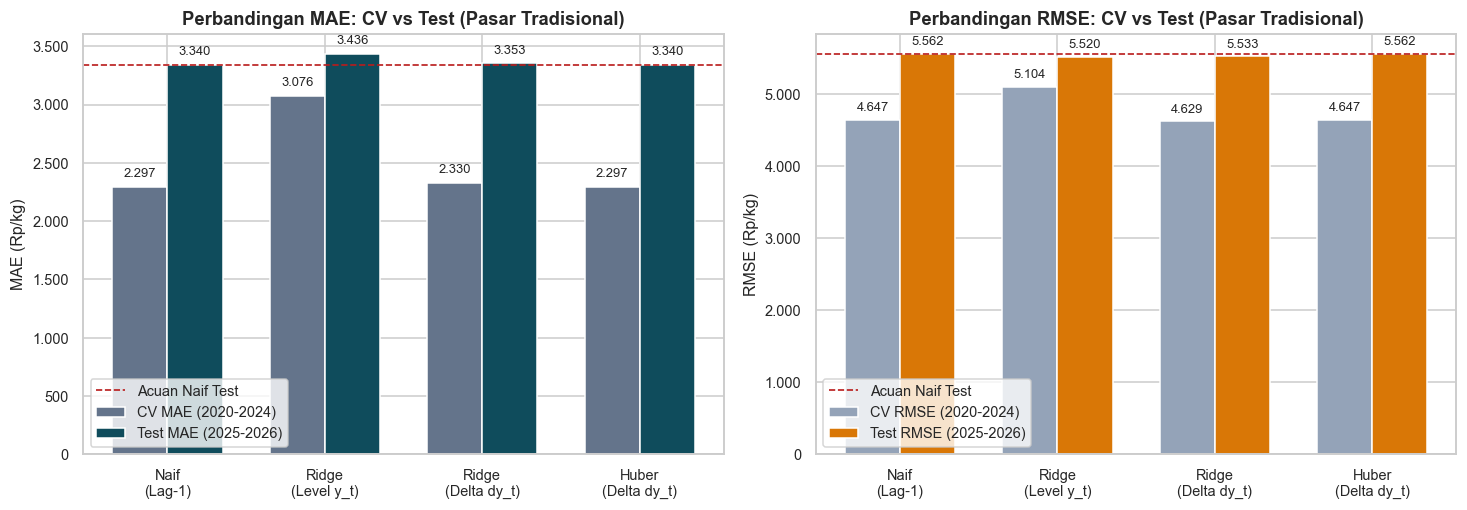

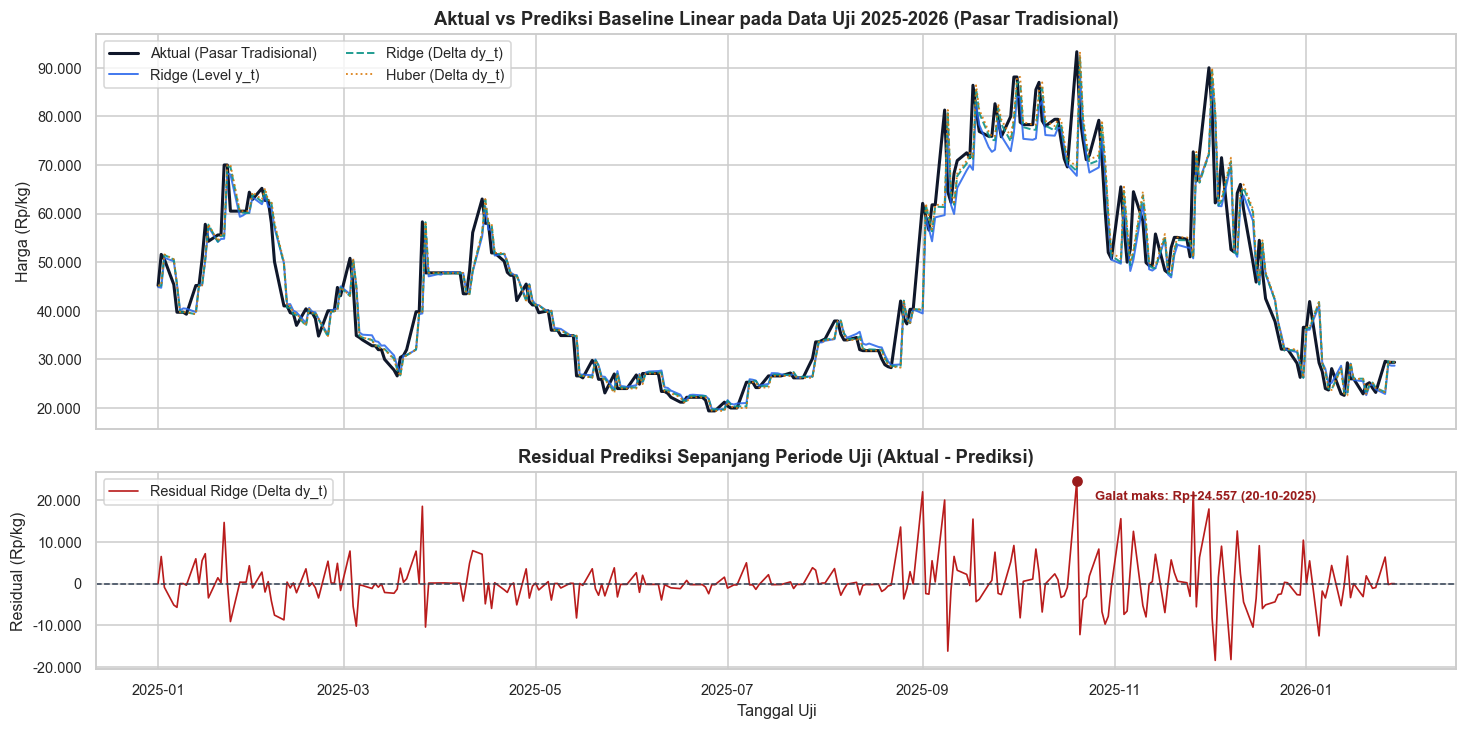

In [4]:
# Plot 1: Komparasi CV MAE, Test MAE, dan Test RMSE pada Pasar Tradisional
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
labels = ["Naif\n(Lag-1)", "Ridge\n(Level y_t)", "Ridge\n(Delta dy_t)", "Huber\n(Delta dy_t)"]
x = np.arange(len(labels))
w = 0.35

b1 = axes[0].bar(x - w/2, res_trad["CV MAE (Rp)"], width=w, label="CV MAE (2020-2024)", color="#64748b")
b2 = axes[0].bar(x + w/2, res_trad["Test MAE (Rp)"], width=w, label="Test MAE (2025-2026)", color="#0f4c5c")
axes[0].axhline(res_trad.loc[0, "Test MAE (Rp)"], color="#b91c1c", linestyle="--", linewidth=1.1, label="Acuan Naif Test")
axes[0].set_title("Perbandingan MAE: CV vs Test (Pasar Tradisional)")
axes[0].set_xticks(x, labels)
axes[0].set_ylabel("MAE (Rp/kg)")
axes[0].yaxis.set_major_formatter(RIBUAN)
axes[0].legend(frameon=True)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 60, f"{h:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=8.5)

b3 = axes[1].bar(x - w/2, res_trad["CV RMSE (Rp)"], width=w, label="CV RMSE (2020-2024)", color="#94a3b8")
b4 = axes[1].bar(x + w/2, res_trad["Test RMSE (Rp)"], width=w, label="Test RMSE (2025-2026)", color="#d97706")
axes[1].axhline(res_trad.loc[0, "Test RMSE (Rp)"], color="#b91c1c", linestyle="--", linewidth=1.1, label="Acuan Naif Test")
axes[1].set_title("Perbandingan RMSE: CV vs Test (Pasar Tradisional)")
axes[1].set_xticks(x, labels)
axes[1].set_ylabel("RMSE (Rp/kg)")
axes[1].yaxis.set_major_formatter(RIBUAN)
axes[1].legend(frameon=True)
for bar in list(b3) + list(b4):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 80, f"{h:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=8.5)

plt.tight_layout()
plt.show()

# Plot 2: Actual vs Predicted & Residual pada Data Uji 2025-2026 (Pasar Tradisional)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13.5, 6.8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.1]})
tgl = pred_trad["Tanggal"]
y_act = pred_trad[TARGET]
y_ridge_lvl = pred_trad["1. Ridge Regression (Level y_t)"]
y_ridge_dlt = pred_trad["2. Ridge Regression (Delta dy_t)"]
y_huber_dlt = pred_trad["3. Huber Linear (Delta dy_t)"]

ax1.plot(tgl, y_act, label="Aktual (Pasar Tradisional)", color="#0f172a", linewidth=2.0)
ax1.plot(tgl, y_ridge_lvl, label="Ridge (Level y_t)", color="#2563eb", linewidth=1.3, alpha=0.85)
ax1.plot(tgl, y_ridge_dlt, label="Ridge (Delta dy_t)", color="#0d9488", linewidth=1.3, linestyle="--", alpha=0.9)
ax1.plot(tgl, y_huber_dlt, label="Huber (Delta dy_t)", color="#d97706", linewidth=1.2, linestyle=":", alpha=0.9)
ax1.set_title("Aktual vs Prediksi Baseline Linear pada Data Uji 2025-2026 (Pasar Tradisional)")
ax1.set_ylabel("Harga (Rp/kg)")
ax1.yaxis.set_major_formatter(RIBUAN)
ax1.legend(loc="upper left", ncol=2, frameon=True)

res_best = y_act - y_ridge_dlt
ax2.plot(tgl, res_best, color="#b91c1c", linewidth=1.1, label="Residual Ridge (Delta dy_t)")
ax2.axhline(0, color="#334155", linestyle="--", linewidth=1.0)
idx_max = res_best.abs().idxmax()
ax2.scatter([tgl.loc[idx_max]], [res_best.loc[idx_max]], color="#991b1b", zorder=5)
ax2.annotate(
    f"Galat maks: Rp{res_best.loc[idx_max]:+,.0f} ({tgl.loc[idx_max].strftime('%d-%m-%Y')})".replace(",", "."),
    xy=(tgl.loc[idx_max], res_best.loc[idx_max]),
    xytext=(12, -12 if res_best.loc[idx_max] > 0 else 10),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#991b1b",
)
ax2.set_title("Residual Prediksi Sepanjang Periode Uji (Aktual - Prediksi)")
ax2.set_ylabel("Residual (Rp/kg)")
ax2.set_xlabel("Tanggal Uji")
ax2.yaxis.set_major_formatter(RIBUAN)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

## 5 · Analisis Koefisien Fitur & Kesimpulan Desain Eksperimen (`D2`)

,Fitur,Koef_Ridge_Level,Koef_Ridge_Delta
0,Harga_Lag1,14650.49,-93.84
1,Harga_PB_Lag1,50.97,-59.15
2,Interaksi_Lag1_x_MusimHujan,-362.76,-56.52
3,Harga_Lag5,496.50,-50.18
4,Akumulasi_Hujan_7H,442.25,46.38
5,Harga_Produsen_Lag1,-16.45,-46.10
6,Harga_Lag20,-19.58,-36.58
7,TE_Pasar_Bulan,210.18,19.71
8,Hari_Menuju_Idul_Fitri,47.12,7.93
9,Level_Rantai_Pasok,0.00,0.00


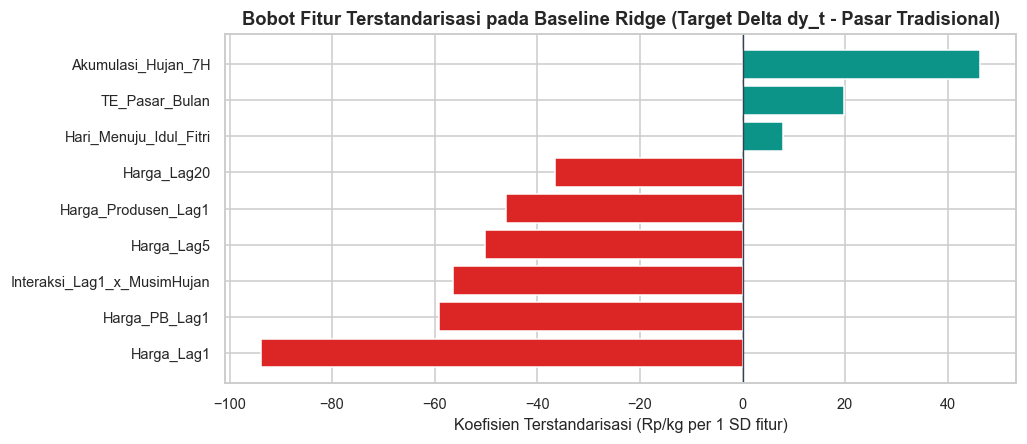

In [5]:
# Ekstrak koefisien terstandarisasi Ridge (Level y_t) & Ridge (Delta dy_t) pada Pasar Tradisional
coef_lvl = models_trad["1. Ridge Regression (Level y_t)"].named_steps["ridge"].coef_
coef_dlt = models_trad["2. Ridge Regression (Delta dy_t)"].named_steps["ridge"].coef_
df_coef = pd.DataFrame({
    "Fitur": FITUR_LINEAR,
    "Koef_Ridge_Level": np.round(coef_lvl, 2),
    "Koef_Ridge_Delta": np.round(coef_dlt, 2),
}).sort_values("Koef_Ridge_Delta", key=np.abs, ascending=False).reset_index(drop=True)
display(df_coef)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
df_plot = df_coef[df_coef["Fitur"] != "Level_Rantai_Pasok"].sort_values("Koef_Ridge_Delta")
colors = ["#dc2626" if v < 0 else "#0d9488" for v in df_plot["Koef_Ridge_Delta"]]
ax.barh(df_plot["Fitur"], df_plot["Koef_Ridge_Delta"], color=colors)
ax.axvline(0, color="#334155", linewidth=0.9)
ax.set_title("Bobot Fitur Terstandarisasi pada Baseline Ridge (Target Delta dy_t - Pasar Tradisional)")
ax.set_xlabel("Koefisien Terstandarisasi (Rp/kg per 1 SD fitur)")
plt.tight_layout()
plt.show()

### Ringkasan Baseline & Rencana Eksperimen Tahap `D2` (`models/train.py`)
1. **Kesimpulan Baseline:** Model linear (**Ridge Level**, **Ridge Delta**, dan **Huber Delta**) menghasilkan $R^2 > 0,90$ pada data uji `2025–2026`, dengan **Ridge (Delta)** sedikit memperbaiki **RMSE** dibanding Naif karena meredam lonjakan ekstrem, namun **MAE rata-rata** masih sangat dekat atau sedikit di atas **Baseline Naif** akibat tingginya proporsi hari harga tetap (*price stickiness*) serta hubungan non-linear cuaca–rantai pasok.
2. **Keputusan Desain Eksperimen Tahap `D2`:**
   - Membandingkan **4 algoritma** (`Naive Persistence` sebagai acuan, `Ridge Regression` sebagai baseline ML, plus 3 model non-linear berbasis pohon: **Random Forest**, **XGBoost**, dan **LightGBM**).
   - Menggunakan **12 fitur terpilih** (`fitur_terpilih_tahap4` di `05_fitur_final_uas.json`, termasuk `Harga_MA7` dan `Harga_MA20` yang aman dari multikolinearitas pada model pohon).
   - Mengoptimalkan *hyperparameter* menggunakan `RandomizedSearchCV` dengan `TimeSeriesSplit(n_splits=5)` (skor MAE) dan mengevaluasi fungsi rugi tahan-outlier (**Huber / L1** vs **L2**) pada target perubahan harga $\Delta y_t$ maupun level harga.
   - Menyimpan model terbaik ke `models/best_model.joblib`, baseline ke `models/baseline_ridge.joblib`, hasil metrik terstruktur ke `models/metrics.json`, dan prediksi uji ke `models/test_predictions.csv` agar terintegrasi langsung ke halaman Streamlit `app/pages/04_Prediksi_Harga.py`.